In [1]:
# load the dataset
import os
import sys
import pandas as pd
import json
load = True
if load:
    data_rand = pd.read_csv("edge_spen/r4_mean_50_rand.csv")
    data_enh = pd.read_csv("r4_mean_50_enh.csv")
    data_base = pd.read_csv("r4_mean_50_base.csv")
    

In [2]:
# Esplorare la struttura dei dati
print("Shape dei dati:")
print(f"rand: {data_rand.shape}")
print(f"enh: {data_enh.shape}")
print(f"base: {data_base.shape}")
print("\nColonne nei dati:")
print(data_rand.columns.tolist())
print("\nPrime righe (rand):")
print(data_rand.head())


Shape dei dati:
rand: (420, 4)
enh: (420, 4)
base: (420, 4)

Colonne nei dati:
['seed', 'beta', 'delta', 'r4_mean_50']

Prime righe (rand):
   seed  beta  delta  r4_mean_50
0     0   3.5    0.3   -1.712852
1     0   3.5    0.4   -0.553591
2     0   3.5    0.5   -0.896008
3     0   3.5    0.6   -1.956333
4     0   3.5    0.7   -2.512121


Beta values (inverted): [np.float64(9.5), np.float64(8.5), np.float64(7.5), np.float64(6.5), np.float64(5.5), np.float64(4.5), np.float64(3.5)]
Delta values: [np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]


/tmp/ipykernel_26205/292128173.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5,
/tmp/ipykernel_26205/292128173.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5,
/tmp/ipykernel_26205/292128173.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5,
/tmp/ipykernel_26205/292128173.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the

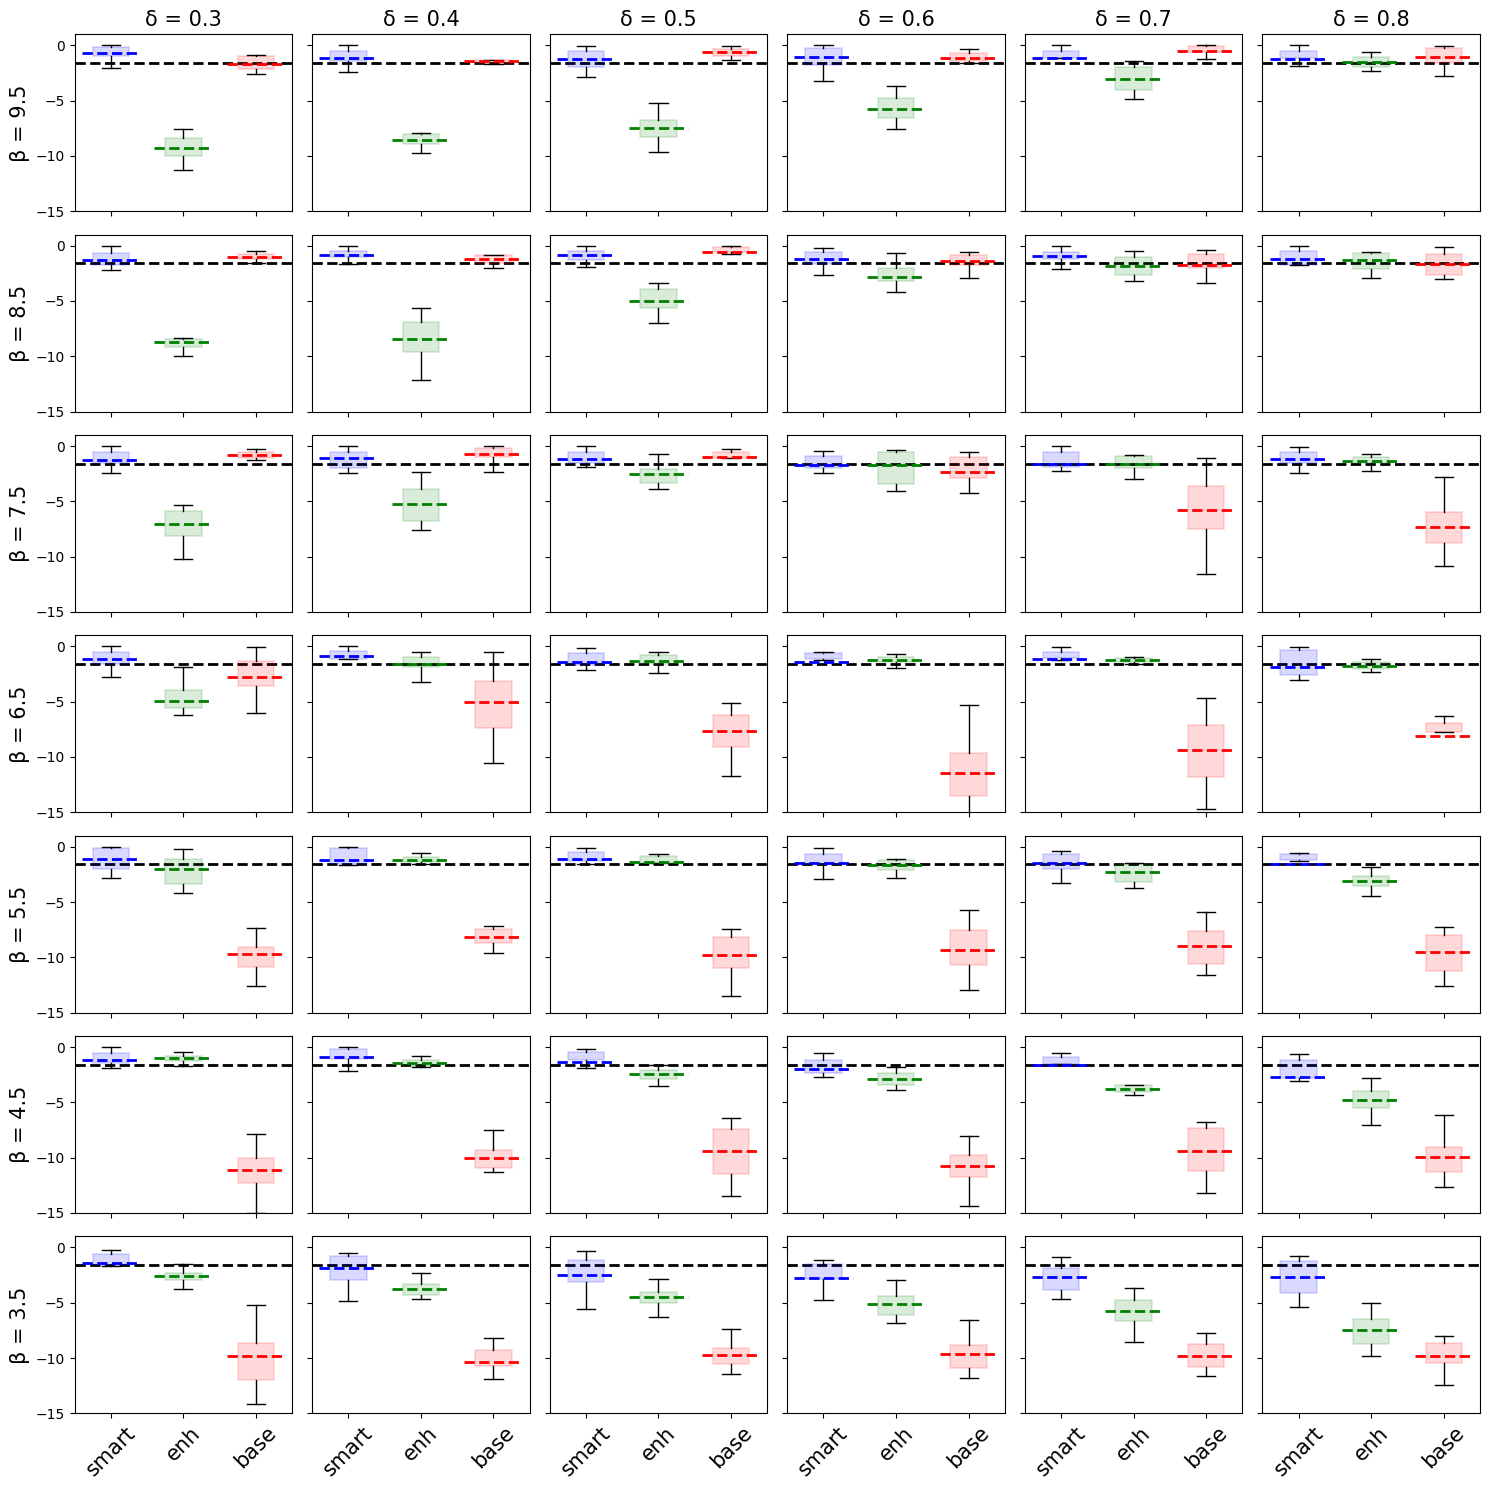

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Add a 'source' column to distinguish the datasets
data_rand['source'] = 'smart'
data_enh['source'] = 'enh'
data_base['source'] = 'base'

# Concatenate the data
data_combined = pd.concat([data_rand, data_enh, data_base], ignore_index=True)

# Get sorted unique values of beta (inverted/descending) and delta (ascending)
betas = sorted(data_combined['beta'].unique(), reverse=True)
deltas = sorted(data_combined['delta'].unique())

print(f"Beta values (inverted): {betas}")
print(f"Delta values: {deltas}")

# Create the gridplot
fig, axes = plt.subplots(len(betas), len(deltas), figsize=(15, 15))

# If there is only one row or column, ensure axes is 2D
if len(betas) == 1:
    axes = axes.reshape(1, -1)
if len(deltas) == 1:
    axes = axes.reshape(-1, 1)

# Iterate through each combination of beta and delta
for i, beta in enumerate(betas):
    for j, delta in enumerate(deltas):
        ax = axes[i, j]
        
        # Filter data for this combination
        mask = (data_combined['beta'] == beta) & (data_combined['delta'] == delta)
        subset = data_combined[mask]
        
        # Prepare data for boxplot
        data_for_boxplot = []
        sources = []
        colors = ['blue', 'green', 'red']
        
        for idx, source in enumerate(['smart', 'enh', 'base']):
            source_data = subset[subset['source'] == source]['r4_mean_50']
            
            if len(source_data) > 0:
                data_for_boxplot.append(source_data.values)
                sources.append(source)
        
        if data_for_boxplot:
            positions = list(range(len(data_for_boxplot)))
            
            # --- UPDATED: meanline abilitata, mediana nascosta ---
            bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, 
                            patch_artist=True, labels=sources, showfliers=False, zorder=2,
                            showmeans=True, meanline=True,
                            medianprops={'linewidth': 0}) # Nasconde la mediana
            
            # Style the boxes with high transparency
            for patch, color in zip(bp['boxes'], colors[:len(data_for_boxplot)]):
                patch.set_facecolor(color)
                patch.set_alpha(0.15)
                patch.set_edgecolor(color)
                patch.set_linewidth(1.2)
            
            # --- UPDATED: Styling e accorciamento delle linee della media ---
            for mean, color in zip(bp['means'], colors[:len(data_for_boxplot)]):
                mean.set_color(color)
                mean.set_linewidth(2)
                
                # Rendi le linee della media più corte della larghezza del box (75% della larghezza)
                x_data = mean.get_xdata() 
                center = np.mean(x_data)
                new_x_data = [center - (center - x_data[0]) * 1.6, center + (x_data[1] - center) * 1.6]
                mean.set_xdata(new_x_data)
        
        # Lo scatter plot per i punti singoli (strip plot) è stato rimosso correttamente
        
        # --- UPDATED: Linea della soglia più visibile e con un tratteggio diverso ('--') ---
        ax.axhline(y=-1.6, color='black', linestyle='--', linewidth=2.0, zorder=1)
        
        # Set titles and labels
        if i == 0:
            ax.set_title(f'δ = {delta}', fontsize=15)
        if j == 0:
            ax.set_ylabel(f'β = {beta}', fontsize=15)
        
        ax.set_ylim([-15, 1])
        ax.tick_params(axis='x', rotation=45, labelsize=15)
        
        # Hide internal axis labels for clarity
        if j > 0:
            ax.set_ylabel('')
            
        if delta >= 0.4:
            ax.tick_params(axis='y', labelleft=False)
            
        if i < len(betas) - 1:
            ax.set_xticklabels([])

plt.tight_layout()
plt.show()

/tmp/ipykernel_26205/744922799.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width,


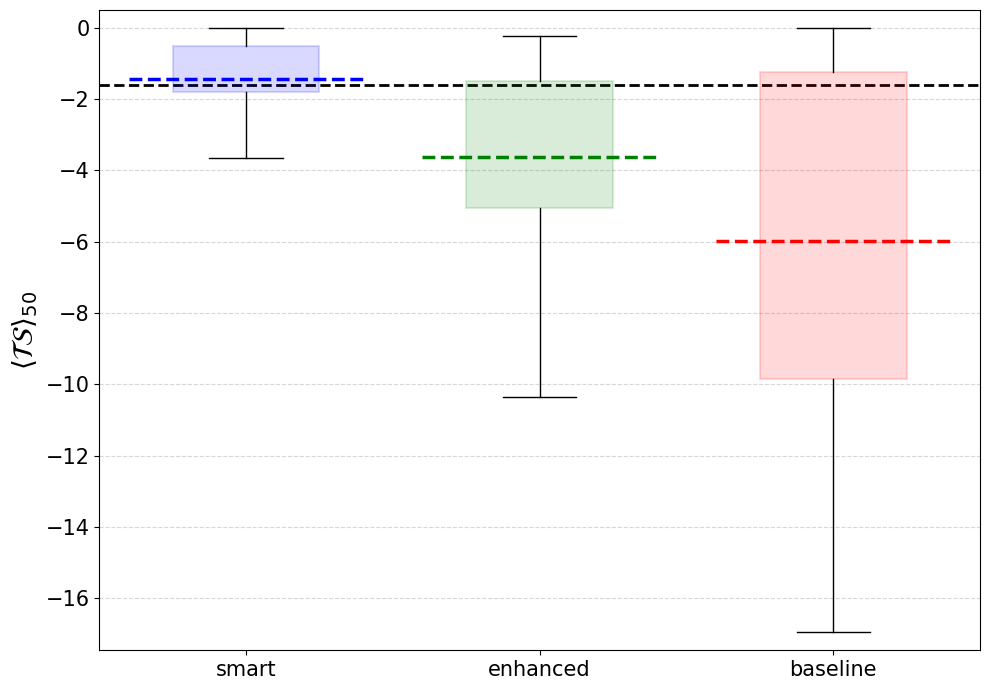

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- FUNZIONE RIUTILIZZABILE PER IL BOXPLOT CUSTOM ---
def ottimizza_boxplot(ax, data_list, labels, colors, width=0.5, scala_media=1.6):
    """
    Crea un boxplot personalizzato su un asse Matplotlib:
    - Mostra la media al posto della mediana
    - Accorcia le linee della media rispetto alla larghezza del box
    - Rimuove i punti singoli (fliers)
    """
    # Creazione del boxplot base con media abilitata e mediana nascosta
    bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width, 
                    patch_artist=True, labels=labels, showfliers=False, zorder=2,
                    showmeans=True, meanline=True, 
                    medianprops={'linewidth': 0}) # Nasconde la mediana
    
    # Styling dei box (trasparenza ed elementi estetici)
    for patch, color in zip(bp['boxes'], colors[:len(data_list)]):
        patch.set_facecolor(color)
        patch.set_alpha(0.15)  
        patch.set_edgecolor(color)
        patch.set_linewidth(1.5)
    
    # Styling e accorciamento simmetrico delle linee della media
    for mean, color in zip(bp['means'], colors[:len(data_list)]):
        mean.set_color(color)
        mean.set_linewidth(2.5)
        
        x_data = mean.get_xdata() 
        center = np.mean(x_data)
        # Riduce la larghezza della linea in base al fattore 'scala_media'
        semilarghezza_nuova = (x_data[1] - center) * scala_media
        mean.set_xdata([center - semilarghezza_nuova, center + semilarghezza_nuova])
        
    return bp

# --- PREPARAZIONE DATI ---
# Add a 'source' column to distinguish the datasets
data_rand['source'] = 'smart'
data_enh['source'] = 'enhanced'
data_base['source'] = 'baseline'

# Concatenate the data
data_combined = pd.concat([data_rand, data_enh, data_base], ignore_index=True)

# Plot setup
fig, ax = plt.subplots(figsize=(10, 7))

sources_list = ['smart', 'enhanced', 'baseline']
colors = ['blue', 'green', 'red']

# Prepare the aggregated data for each source
data_for_boxplot = []
for source in sources_list:
    source_data = data_combined[data_combined['source'] == source]['r4_mean_50'].values
    data_for_boxplot.append(source_data)

# --- COSTRUZIONE GRAFICO ---
# Uso della funzione custom (lo scatter plot interno è stato rimosso automaticamente)
ottimizza_boxplot(ax, data_for_boxplot, labels=sources_list, colors=colors, width=0.5, scala_media=1.6)

# --- SOGLIA E FORMATTAZIONE ---
# Linea della soglia più visibile e con un tratteggio diverso ('--')
ax.axhline(y=-1.6, color='black', linestyle='--', linewidth=2.0, zorder=1)

# Global plot formatting
ax.set_ylabel(r'$\langle \mathcal{TS} \rangle_{50}$', fontsize=20)
ax.set_ylim([data_combined['r4_mean_50'].min() -0.5, data_combined['r4_mean_50'].max() +0.5])
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=1)

# Clean up axis appearance
ax.tick_params(axis='x', labelsize=15, rotation=0)
ax.tick_params(axis='y', labelsize=15)

plt.tight_layout()
plt.show()

# pop and pod

In [10]:
pop_pod_rand = pd.read_csv("edge_spen/pop_pod_last_rand.csv")
pop_pod_base = pd.read_csv("pop_pod_last_base.csv")

/tmp/ipykernel_89049/2924058464.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width,
/tmp/ipykernel_89049/2924058464.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width,
/tmp/ipykernel_89049/2924058464.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width,
/tmp/ipykernel_89049/2924058464.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplo

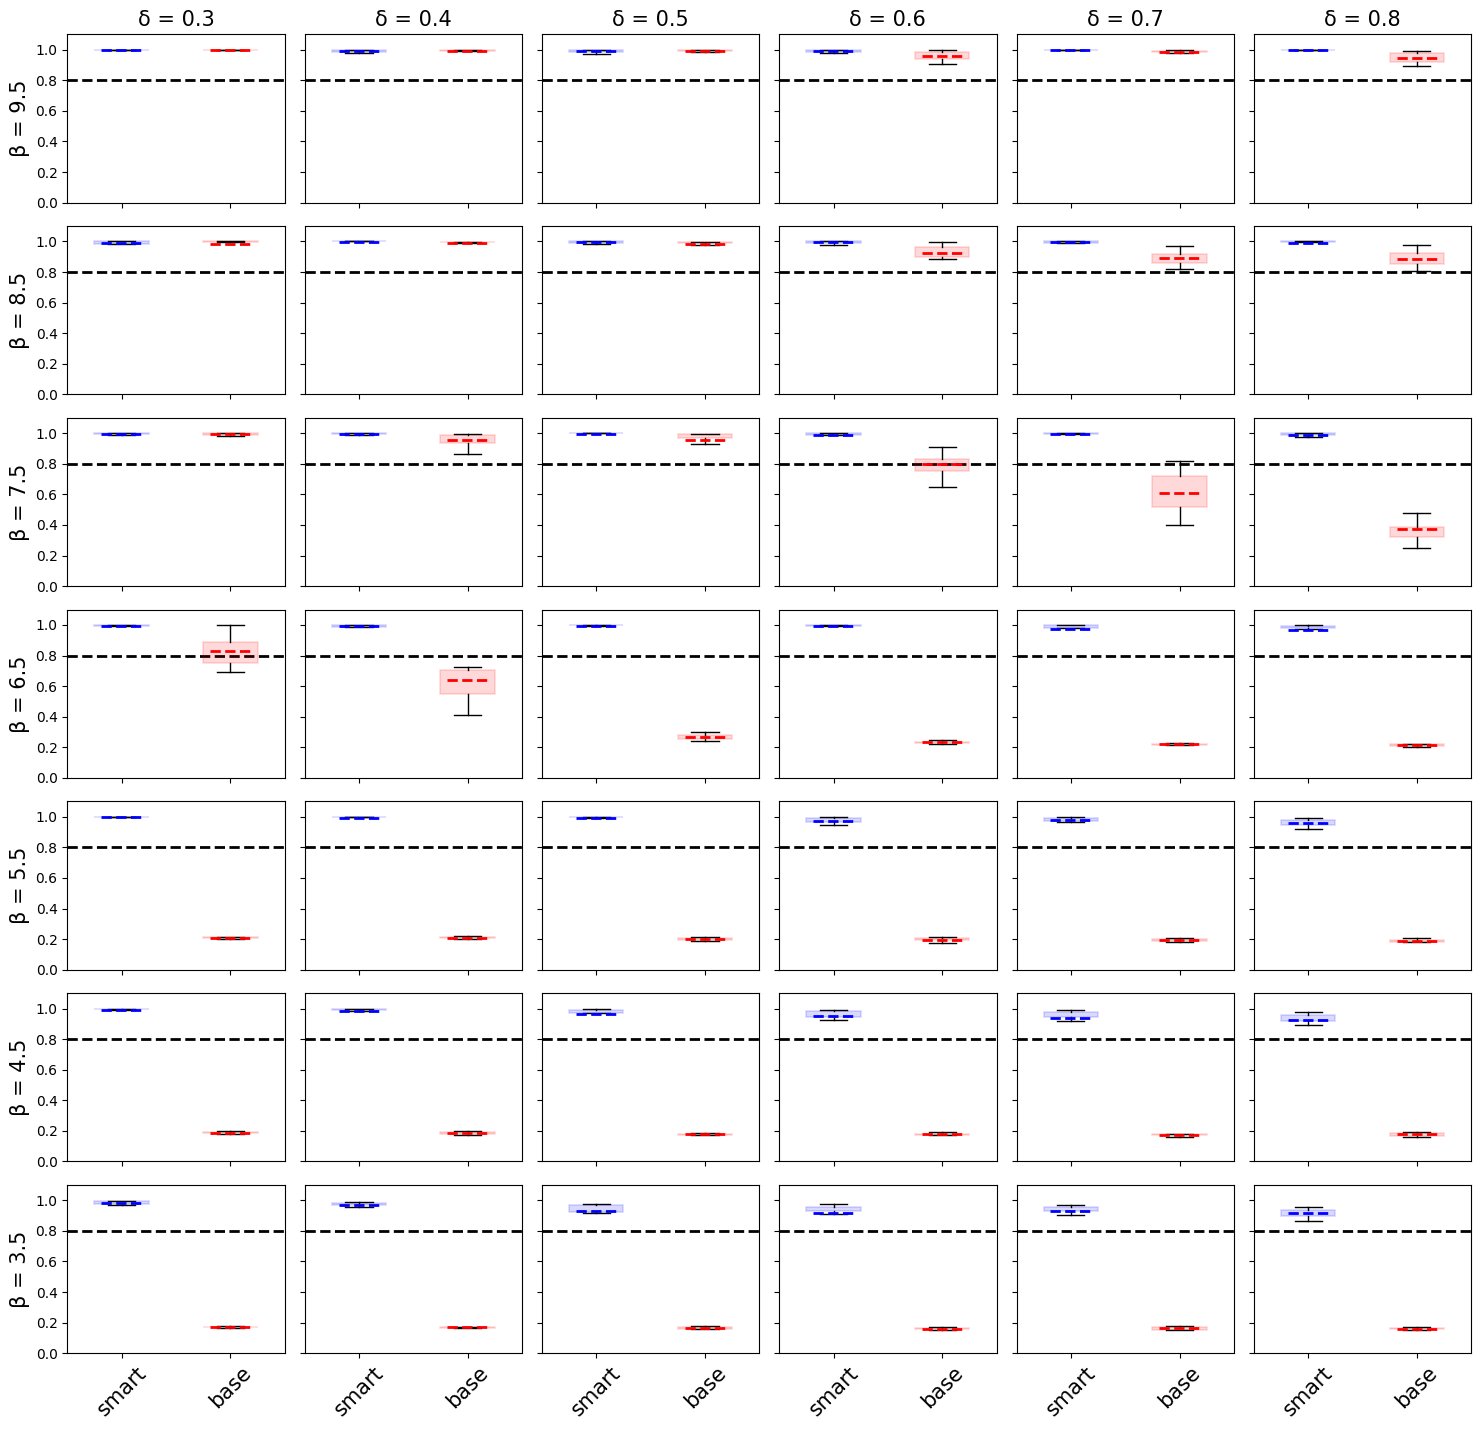

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- FUNZIONE RIUTILIZZABILE PER IL BOXPLOT CUSTOM ---
def ottimizza_boxplot(ax, data_list, labels, colors, width=0.5, scala_media=0.75):
    """
    Personalizza il boxplot sull'asse selezionato:
    - Mostra la media al posto della mediana
    - Accorcia le linee della media
    - Rimuove i punti singoli (fliers)
    """
    bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width, 
                    patch_artist=True, labels=labels, showfliers=False, zorder=2,
                    showmeans=True, meanline=True, 
                    medianprops={'linewidth': 0}) # Nasconde la mediana
    
    # Styling dei box
    for patch, color in zip(bp['boxes'], colors[:len(data_list)]):
        patch.set_facecolor(color)
        patch.set_alpha(0.15)
        patch.set_edgecolor(color)
        patch.set_linewidth(1.2)
    
    # Styling e accorciamento delle linee della media
    for mean, color in zip(bp['means'], colors[:len(data_list)]):
        mean.set_color(color)
        mean.set_linewidth(2)
        
        x_data = mean.get_xdata() 
        center = np.mean(x_data)
        semilarghezza_nuova = (x_data[1] - center) * scala_media
        mean.set_xdata([center - semilarghezza_nuova, center + semilarghezza_nuova])
        
    return bp

# --- PREPARAZIONE DATI ---
pop_pod_rand['source'] = 'smart'
pop_pod_base['source'] = 'base'
pop_pod_combined = pd.concat([pop_pod_rand, pop_pod_base], ignore_index=True)

betas = sorted(pop_pod_combined['beta'].unique(), reverse=True)
deltas = sorted(pop_pod_combined['delta'].unique())

# Creazione della griglia di plot
fig, axes = plt.subplots(len(betas), len(deltas), figsize=(15, 15))

if len(betas) == 1:
    axes = axes.reshape(1, -1)
if len(deltas) == 1:
    axes = axes.reshape(-1, 1)

# Ciclo principale sui subplot
for i, beta in enumerate(betas):
    for j, delta in enumerate(deltas):
        ax = axes[i, j]
        
        mask = (pop_pod_combined['beta'] == beta) & (pop_pod_combined['delta'] == delta)
        subset = pop_pod_combined[mask]
        
        data_for_boxplot = []
        sources = []
        colors = ['blue', 'red']
        
        for source in ['smart', 'base']:
            source_data = subset[subset['source'] == source]['pop_last']
            if len(source_data) > 0:
                data_for_boxplot.append(source_data.values)
                sources.append(source)
        
        if data_for_boxplot:
            # Chiamata alla funzione custom (rimuove automaticamente lo scatter plot interno)
            ottimizza_boxplot(ax, data_for_boxplot, labels=sources, colors=colors, width=0.5, scala_media=0.75)
            
        # Formattazione titoli e label di riga/colonna
        if i == 0:
            ax.set_title(f'δ = {delta}', fontsize=15)
        if j == 0:
            ax.set_ylabel(f'β = {beta}', fontsize=15)
        
        ax.set_ylim([min(pop_pod_combined['pop_last'].min() - 0.1, 0), pop_pod_combined['pop_last'].max() + 0.1])
        ax.tick_params(axis='x', rotation=45, labelsize=15)
        
        if j > 0:
            ax.set_ylabel('')
            
        if delta >= 0.4:
            ax.tick_params(axis='y', labelleft=False)
            
        if i < len(betas) - 1:
            ax.set_xticklabels([])

# --- UPDATED: Linea della soglia a 0.8 più visibile e con tratteggio '--' ---
for ax_row in axes.flatten():
    ax_row.axhline(y=0.8, color='black', linestyle='--', linewidth=2.0, zorder=1)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

/tmp/ipykernel_89049/1948802200.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources_list, showfliers=False, zorder=2)


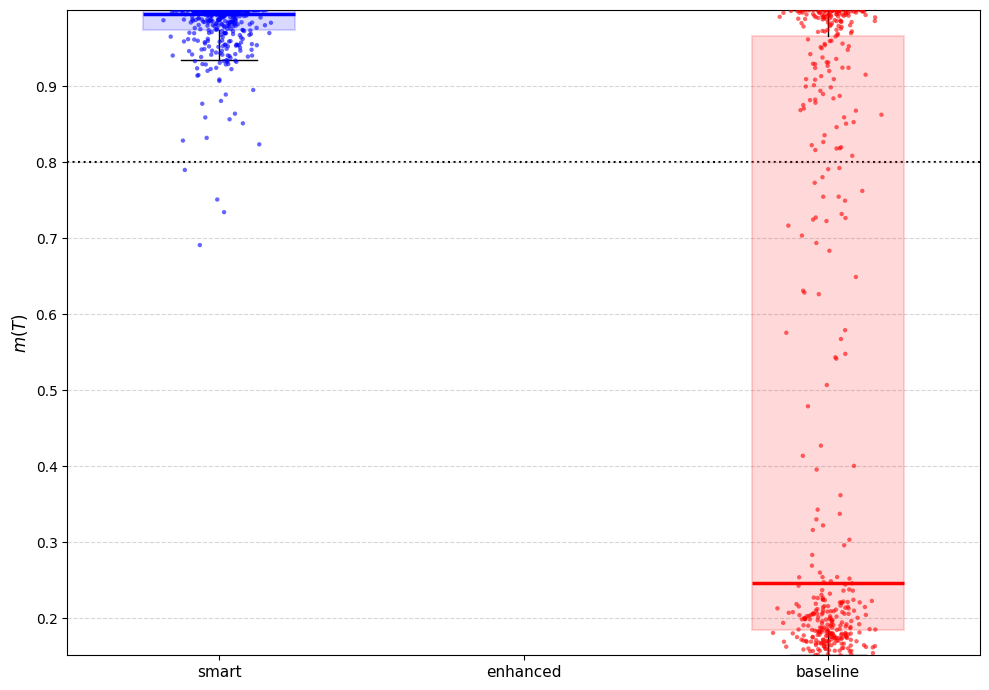

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# GLOBAL: aggregated boxplot for 'pop_last' across scenarios
pop_pod_rand['source'] = 'smart'
pop_pod_base['source'] = 'baseline'
pop_pod_combined = pd.concat([pop_pod_rand, pop_pod_base], ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 7))
sources_list = ['smart', 'enhanced', 'baseline']
colors = ['blue', 'green', 'red']
positions = range(len(sources_list))
data_for_boxplot = []
for source in sources_list:
    source_data = pop_pod_combined[pop_pod_combined['source'] == source]['pop_last'].values
    data_for_boxplot.append(source_data)
bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources_list, showfliers=False, zorder=2)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.15)
    patch.set_edgecolor(color)
    patch.set_linewidth(1.5)
for median, color in zip(bp['medians'], colors):
    median.set_color(color)
    median.set_linewidth(2.5)
for idx, source_data in enumerate(data_for_boxplot):
    jitter = np.random.normal(0, 0.06, size=len(source_data))
    x_positions = np.full(len(source_data), positions[idx]) + jitter
    ax.scatter(x_positions, source_data, color=colors[idx], alpha=0.6, edgecolors='none', s=10, zorder=3)
ax.set_ylabel(r'$m(T)$', fontsize=12)
# ax.set_title(r'Global Distribution of $m(T)$ by Scenario (Threshold = 0.8)', fontsize=14, fontweight='bold')
ax.set_ylim([pop_pod_combined['pop_last'].min(), pop_pod_combined['pop_last'].max()])
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=1)
ax.axhline(y=0.8, color='black', linestyle=':', linewidth=1.5, zorder=1)
ax.tick_params(axis='x', labelsize=11)
plt.tight_layout()
plt.show()

/tmp/ipykernel_89049/2924058464.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width,
/tmp/ipykernel_89049/2924058464.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width,
/tmp/ipykernel_89049/2924058464.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_list, positions=range(len(data_list)), widths=width,
/tmp/ipykernel_89049/2924058464.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplo

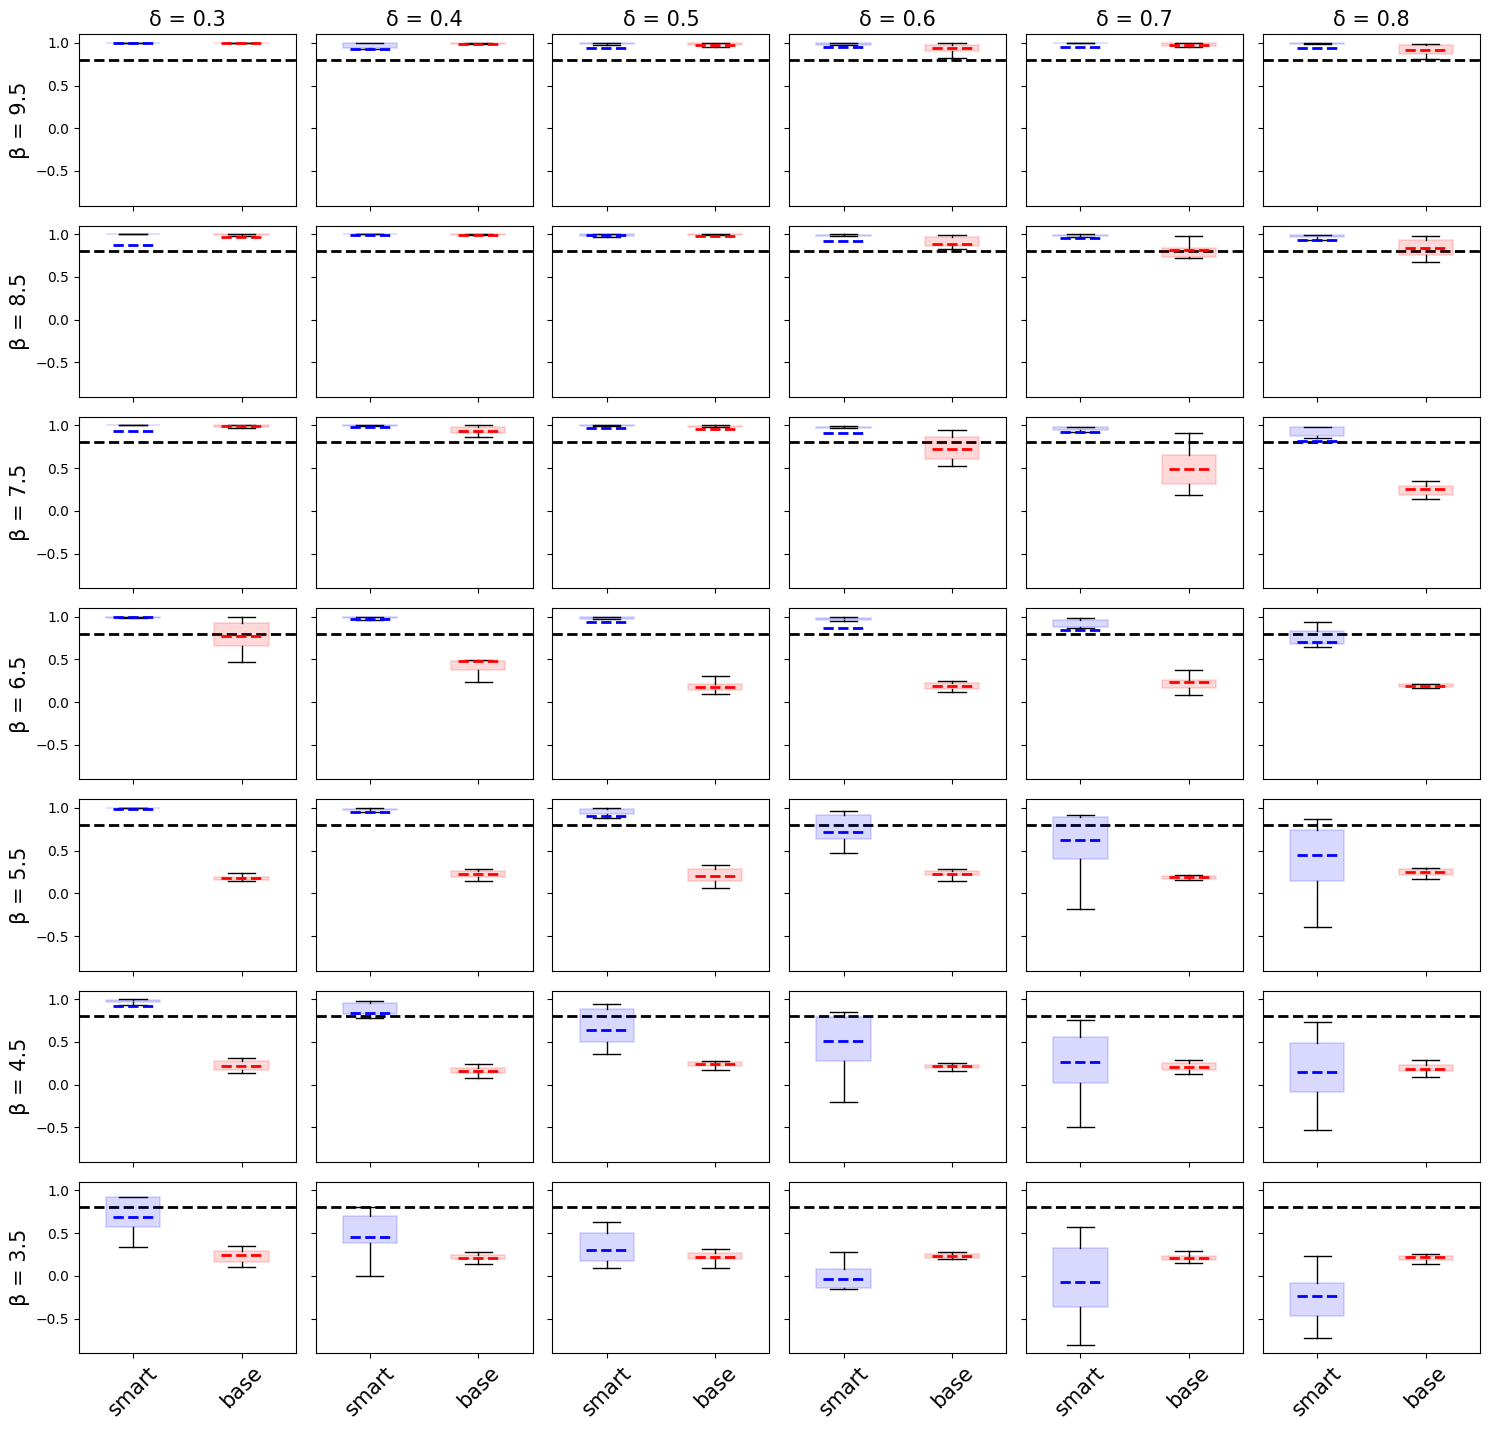

In [26]:
# --- PREPARAZIONE DATI ---
pop_pod_rand['source'] = 'smart'
pop_pod_base['source'] = 'base'
pop_pod_combined = pd.concat([pop_pod_rand, pop_pod_base], ignore_index=True)

betas = sorted(pop_pod_combined['beta'].unique(), reverse=True)
deltas = sorted(pop_pod_combined['delta'].unique())

# Creazione della griglia di plot
fig, axes = plt.subplots(len(betas), len(deltas), figsize=(15, 15))

if len(betas) == 1:
    axes = axes.reshape(1, -1)
if len(deltas) == 1:
    axes = axes.reshape(-1, 1)

# Ciclo principale sui subplot
for i, beta in enumerate(betas):
    for j, delta in enumerate(deltas):
        ax = axes[i, j]
        
        mask = (pop_pod_combined['beta'] == beta) & (pop_pod_combined['delta'] == delta)
        subset = pop_pod_combined[mask]
        
        data_for_boxplot = []
        sources = []
        colors = ['blue', 'red']
        
        for source in ['smart', 'base']:
            source_data = subset[subset['source'] == source]['pod_last']
            if len(source_data) > 0:
                data_for_boxplot.append(source_data.values)
                sources.append(source)
        
        if data_for_boxplot:
            # Chiamata alla funzione custom (rimuove automaticamente lo scatter plot interno)
            ottimizza_boxplot(ax, data_for_boxplot, labels=sources, colors=colors, width=0.5, scala_media=0.75)
            
        # Formattazione titoli e label di riga/colonna
        if i == 0:
            ax.set_title(f'δ = {delta}', fontsize=15)
        if j == 0:
            ax.set_ylabel(f'β = {beta}', fontsize=15)
        
        ax.set_ylim([min(pop_pod_combined['pod_last'].min() - 0.1, 0), pop_pod_combined['pod_last'].max() + 0.1])
        ax.tick_params(axis='x', rotation=45, labelsize=15)
        
        if j > 0:
            ax.set_ylabel('')
            
        if delta >= 0.4:
            ax.tick_params(axis='y', labelleft=False)
            
        if i < len(betas) - 1:
            ax.set_xticklabels([])

# --- UPDATED: Linea della soglia a 0.8 più visibile e con tratteggio '--' ---
for ax_row in axes.flatten():
    ax_row.axhline(y=0.8, color='black', linestyle='--', linewidth=2.0, zorder=1)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

/tmp/ipykernel_89049/5799869.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources_list, showfliers=False, zorder=2)


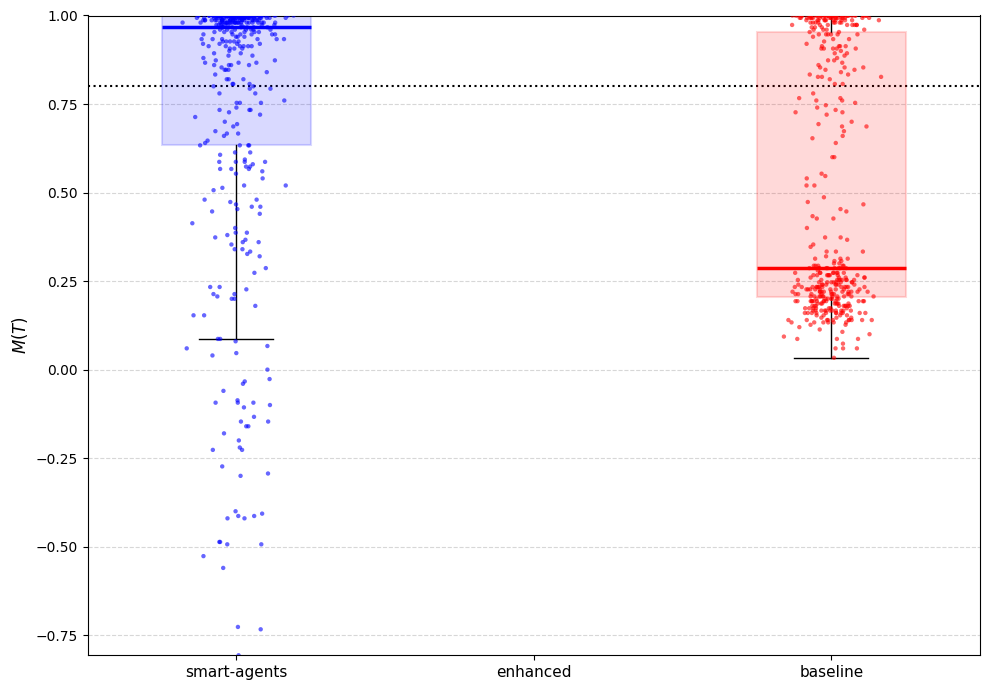

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# GLOBAL: aggregated boxplot for 'pop_last' across scenarios
pop_pod_rand['source'] = 'smart-agents'
pop_pod_base['source'] = 'baseline'
pop_pod_combined = pd.concat([pop_pod_rand, pop_pod_base], ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 7))
sources_list = ['smart-agents', 'enhanced', 'baseline']
colors = ['blue', 'green', 'red']
positions = range(len(sources_list))
data_for_boxplot = []
for source in sources_list:
    source_data = pop_pod_combined[pop_pod_combined['source'] == source]['pod_last'].values
    data_for_boxplot.append(source_data)
bp = ax.boxplot(data_for_boxplot, positions=positions, widths=0.5, patch_artist=True, labels=sources_list, showfliers=False, zorder=2)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.15)
    patch.set_edgecolor(color)
    patch.set_linewidth(1.5)
for median, color in zip(bp['medians'], colors):
    median.set_color(color)
    median.set_linewidth(2.5)
for idx, source_data in enumerate(data_for_boxplot):
    jitter = np.random.normal(0, 0.06, size=len(source_data))
    x_positions = np.full(len(source_data), positions[idx]) + jitter
    ax.scatter(x_positions, source_data, color=colors[idx], alpha=0.6, edgecolors='none', s=10, zorder=3)
ax.set_ylabel(r'$M(T)$', fontsize=12)
# ax.set_title(r'Global Distribution of $M by Scenario (Threshold = 0.8)', fontsize=14, fontweight='bold')
ax.set_ylim([pop_pod_combined['pod_last'].min(), pop_pod_combined['pod_last'].max()])
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=1)
ax.axhline(y=0.8, color='black', linestyle=':', linewidth=1.5, zorder=1)
ax.tick_params(axis='x', labelsize=11)
plt.tight_layout()
plt.show()